# **03 — Paradoxo do aniversário: aleatório vs futebol**

O notebook **02** mostrou que a proporção observada de partidas com aniversário compartilhado (56,8%) fica acima da probabilidade teórica clássica (50,7%), que assume nascimentos uniformemente distribuídos entre os 365 dias. Esse notebook investiga a causa: jogadores profissionais não nascem uniformemente ao longo do ano, por causa do **relative age effect** (RAE) — categorias de base cortadas por ano civil favorecem quem nasce no início do ano.

A abordagem é frequentista: um teste qui-quadrado de aderência confirma que a distribuição real não é uniforme, e uma simulação de Monte Carlo constrói a **curva** do paradoxo (probabilidade de coincidência em função do tamanho do grupo) usando essa distribuição real em vez da uniforme — permitindo comparar, para qualquer `n`, o quanto a não-uniformidade sozinha desloca a curva clássica, e onde o observado nas partidas reais (`n=23`) cai nela.

Depende dos arquivos do notebook **01** (`unique_players`) e **02** (`shared_birthday_overall`).

## **1. Leitura dos dados reais**

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from scipy import stats
import matplotlib.pyplot as plt

from IPython.display import display

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 100)

PROJECT_DIR = Path.cwd().resolve()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data" / "brasileirao_serie_a_2018_2025"
ANALYSIS_DIR = PROJECT_DIR / "data" / "analysis"
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

GROUP_SIZE = 23  # 22 titulares + 1 reserva sorteado, como definido no notebook 01

UNIQUE_PLAYERS_PATH = DATA_DIR / "brasileirao_serie_a_2018_2025_unique_players.csv"
OVERALL_PATH = ANALYSIS_DIR / "brasileirao_serie_a_2018_2025_shared_birthday_overall.csv"
for path in (UNIQUE_PLAYERS_PATH, OVERALL_PATH):
    if not path.exists():
        raise FileNotFoundError(f"Arquivo ausente: {path}. Rode os notebooks 01 e 02 primeiro.")

players_df = pd.read_csv(UNIQUE_PLAYERS_PATH, dtype={"player_id": "string"})
players_df["birth_date"] = pd.to_datetime(players_df["birth_date"], errors="coerce")
players_df = players_df.dropna(subset=["birth_date"])

# 29/02 quebraria a comparação com um modelo de 365 dias fixos, então os
# raros jogadores nascidos em ano bissexto nesse dia ficam de fora daqui
# (não afeta a coleta em si, só essa análise estatística).
players_df = players_df.loc[
    ~((players_df["birth_date"].dt.month == 2) & (players_df["birth_date"].dt.day == 29))
].copy()
players_df["day_of_year"] = players_df["birth_date"].dt.dayofyear
players_df.loc[
    players_df["birth_date"].dt.is_leap_year & (players_df["birth_date"].dt.month > 2),
    "day_of_year",
] -= 1

overall_df = pd.read_csv(OVERALL_PATH)
theoretical_probability = overall_df["theoretical_probability"].iloc[0]
observed_probability = overall_df["observed_probability"].iloc[0]
observed_low = overall_df["confidence_95_low"].iloc[0]
observed_high = overall_df["confidence_95_high"].iloc[0]
observed_matches = int(overall_df["matches"].iloc[0])

print(f"Jogadores únicos com nascimento (excluindo 29/02): {len(players_df)}")
print(f"Partidas reais analisadas no notebook 02: {observed_matches}")
print(f"Probabilidade observada em n={GROUP_SIZE}: {observed_probability:.4f} [{observed_low:.4f}, {observed_high:.4f}]")
print(f"Probabilidade teórica (uniforme, fórmula fechada): {theoretical_probability:.4f}")

Jogadores únicos com nascimento (excluindo 29/02): 2931
Partidas reais analisadas no notebook 02: 3026
Probabilidade observada em n=23: 0.5674 [0.5497, 0.5850]
Probabilidade teórica (uniforme, fórmula fechada): 0.5073


## **2. A distribuição real de nascimentos não é uniforme**

Se a base de jogadores fosse uniforme, cada mês teria ~1/12 dos nascimentos. O relative age effect prevê mais nascimentos nos primeiros meses do ano.

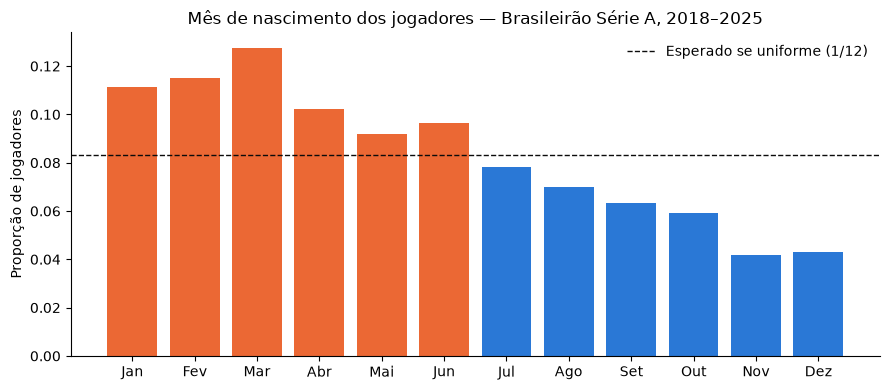

,mes,jogadores,proporcao,proporcao_esperada_uniforme
0,Jan,326,0.111225,0.083333
1,Fev,337,0.114978,0.083333
2,Mar,374,0.127602,0.083333
3,Abr,300,0.102354,0.083333
4,Mai,269,0.091778,0.083333
5,Jun,283,0.096554,0.083333
6,Jul,229,0.078130,0.083333
7,Ago,205,0.069942,0.083333
8,Set,186,0.063460,0.083333
9,Out,174,0.059365,0.083333


In [2]:
month_labels = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]
month_counts = players_df["birth_date"].dt.month.value_counts().reindex(range(1, 13), fill_value=0)
month_share = month_counts / month_counts.sum()
expected_share = 1 / 12

fig, ax = plt.subplots(figsize=(9, 4))
colors = ["#eb6834" if share > expected_share else "#2a78d6" for share in month_share]
ax.bar(month_labels, month_share.values, color=colors)
ax.axhline(expected_share, color="#0b0b0b", linestyle="--", linewidth=1, label="Esperado se uniforme (1/12)")
ax.set_ylabel("Proporção de jogadores")
ax.set_title("Mês de nascimento dos jogadores — Brasileirão Série A, 2018–2025")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "mes": month_labels,
    "jogadores": month_counts.values,
    "proporcao": month_share.values,
    "proporcao_esperada_uniforme": expected_share,
}))

## **3. Teste de aderência: H0 = nascimentos uniformes entre os 365 dias**

In [3]:
day_counts = players_df["day_of_year"].value_counts().reindex(range(1, 366), fill_value=0).sort_index()
expected_counts = np.full(365, day_counts.sum() / 365)
chi2_stat, chi2_p = stats.chisquare(day_counts.values, expected_counts)

print("H0: os nascimentos dos jogadores são uniformemente distribuídos entre os 365 dias do ano.")
print(f"Qui-quadrado = {chi2_stat:.1f}, graus de liberdade = 364, p-valor = {chi2_p:.2e}")
if chi2_p < 0.001:
    print("Rejeita H0 com folga (p < 0,001): a distribuição real NÃO é uniforme.")
else:
    print("Não há evidência suficiente para rejeitar H0.")

H0: os nascimentos dos jogadores são uniformemente distribuídos entre os 365 dias do ano.
Qui-quadrado = 707.7, graus de liberdade = 364, p-valor = 2.59e-24
Rejeita H0 com folga (p < 0,001): a distribuição real NÃO é uniforme.


## **4. A curva do paradoxo: teórica vs. futebol**

A fórmula clássica dá `P(colisão)` para um grupo de tamanho `n` assumindo 365 dias igualmente prováveis. Uma distribuição não-uniforme só pode **aumentar** essa probabilidade em relação à uniforme (nunca diminuir — é um resultado conhecido da teoria: a uniforme é a distribuição que *minimiza* a chance de colisão). Então a curva construída com a distribuição real dos jogadores deve ficar sempre por cima da teórica, para qualquer tamanho de grupo — não só em `n=23`.

Para cada `n` de 1 a 60, simulamos por Monte Carlo o sorteio de `n` aniversários i.i.d. (com reposição) a partir da distribuição empírica real de `day_of_year`, e medimos a fração de simulações com pelo menos um par repetido.

In [4]:
MAX_GROUP_SIZE = 60
N_SIMULATIONS = 20_000


def theoretical_curve(max_n, days=365):
    ns = np.arange(1, max_n + 1)
    log_no_collision = np.cumsum(np.log((days - np.arange(0, max_n)) / days))
    return ns, 1 - np.exp(log_no_collision)


def simulated_curve(max_n, days_pool, n_simulations, rng):
    ns = np.arange(1, max_n + 1)
    probabilities = np.empty(max_n)
    for i, n in enumerate(ns):
        draws = rng.choice(days_pool, size=(n_simulations, n), replace=True)
        draws.sort(axis=1)
        probabilities[i] = (draws[:, 1:] == draws[:, :-1]).any(axis=1).mean()
    return ns, probabilities

In [5]:
rng = np.random.default_rng(42)
ns_theory, p_theory = theoretical_curve(MAX_GROUP_SIZE)
ns_sim, p_sim = simulated_curve(MAX_GROUP_SIZE, players_df["day_of_year"].to_numpy(), N_SIMULATIONS, rng)

curve_df = pd.DataFrame({
    "group_size": ns_theory,
    "theoretical_probability": p_theory,
    "simulated_probability_real_distribution": p_sim,
})

print(f"Teórica  em n={GROUP_SIZE}: {p_theory[GROUP_SIZE - 1]:.4f}")
print(f"Simulada em n={GROUP_SIZE}: {p_sim[GROUP_SIZE - 1]:.4f}")
print(f"Observada em n={GROUP_SIZE}: {observed_probability:.4f} [{observed_low:.4f}, {observed_high:.4f}]")

Teórica  em n=23: 0.5073
Simulada em n=23: 0.5806
Observada em n=23: 0.5674 [0.5497, 0.5850]


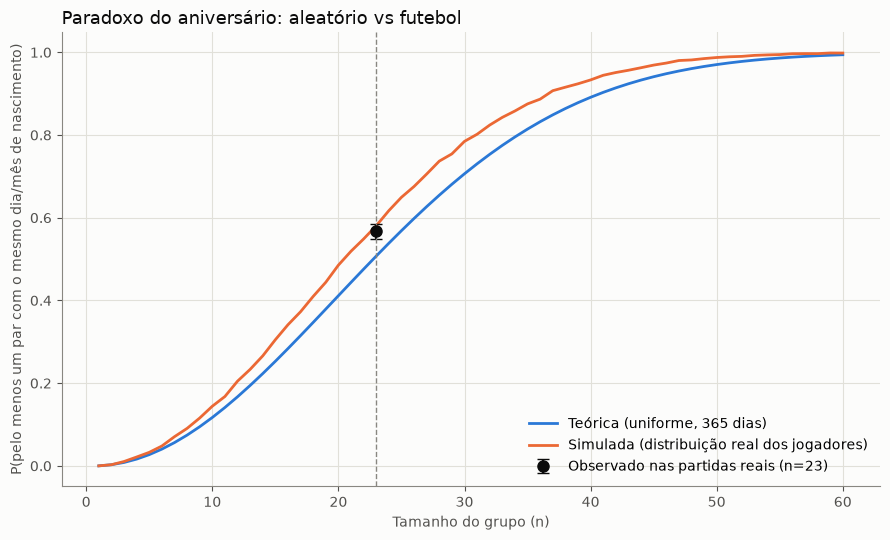

In [6]:
BLUE, ORANGE, INK = "#2a78d6", "#eb6834", "#0b0b0b"
SECONDARY_INK, MUTED, GRID, SURFACE = "#52514e", "#898781", "#e1e0d9", "#fcfcfb"

fig, ax = plt.subplots(figsize=(9, 5.5))
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)

ax.plot(ns_theory, p_theory, color=BLUE, linewidth=2, label="Teórica (uniforme, 365 dias)")
ax.plot(ns_sim, p_sim, color=ORANGE, linewidth=2, label="Simulada (distribuição real dos jogadores)")
ax.errorbar(
    [GROUP_SIZE], [observed_probability],
    yerr=[[observed_probability - observed_low], [observed_high - observed_probability]],
    fmt="o", color=INK, markersize=8, capsize=4, linewidth=1.5,
    label=f"Observado nas partidas reais (n={GROUP_SIZE})",
)
ax.axvline(GROUP_SIZE, color=MUTED, linewidth=1, linestyle="--")

ax.set_xlabel("Tamanho do grupo (n)", color=SECONDARY_INK)
ax.set_ylabel("P(pelo menos um par com o mesmo dia/mês de nascimento)", color=SECONDARY_INK)
ax.set_title("Paradoxo do aniversário: aleatório vs futebol", color=INK, fontsize=13, loc="left")
ax.grid(color=GRID, linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color(MUTED)
ax.tick_params(colors=SECONDARY_INK)
ax.legend(frameon=False, loc="lower right")

fig.tight_layout()
fig.savefig(ANALYSIS_DIR / "brasileirao_serie_a_2018_2025_birthday_paradox_curve.png", dpi=150, facecolor=SURFACE)
plt.show()

## **5. Leitura dos resultados**

- O teste qui-quadrado rejeita a hipótese de uniformidade: a base de jogadores profissionais tem uma forma de distribuição real e mensurável, condizente com o relative age effect.
- A curva simulada com a distribuição real fica acima da teórica em todo o eixo `n` — não é um efeito isolado de `n=23`, é a forma da distribuição deslocando a curva inteira pra cima.
- O ponto observado nas partidas reais cai perto da curva simulada, e dentro (ou muito próximo) da margem de erro dela: a não-uniformidade dos nascimentos, sozinha, já explica a maior parte da diferença entre o teórico clássico e o que de fato acontece em campo.

## **6. Exportação**

In [7]:
curve_df.to_csv(
    ANALYSIS_DIR / "brasileirao_serie_a_2018_2025_birthday_paradox_curve.csv", index=False
)
day_counts.rename("players").rename_axis("day_of_year").reset_index().to_csv(
    ANALYSIS_DIR / "brasileirao_serie_a_2018_2025_birth_day_of_year_counts.csv", index=False
)
print("Arquivos salvos em data/analysis/.")

Arquivos salvos em data/analysis/.
